Nama: Johansen Tan
NIM: 2702241710

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
df = pd.read_csv('imbalanced_cleaned.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  2000 non-null   int64 
 1   content     2000 non-null   object
 2   score       2000 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 47.0+ KB


In [ ]:
df.head()

,Unnamed: 0,content,score
0,0,"this is a Nice app, what is the difference bet...",5
1,1,Please add the option of swiss tournament in t...,3
2,2,Put customization back on for pieces and board.,1
3,3,I think it is a great app to play chess on esp...,5
4,4,Da ROOOK!!!!!!!!,5


# 3. Cleaning and Lemmatization

In [ ]:
import re

# Non Words Cleaning
def cleaning(text):
  text = str(text)

  # Replace all except alphabets and space with spaces
  text = re.sub(r'[^a-zA-Z\s]', ' ', text)
  # Replace multiple spaces with one space and lower
  text = re.sub(r'\s+', ' ', text).strip().lower()

  return text

df['content'] = df['content'].apply(cleaning)

df.head(10)

,Unnamed: 0,content,score
0,0,this is a nice app what is the difference betw...,5
1,1,please add the option of swiss tournament in t...,3
2,2,put customization back on for pieces and board,1
3,3,i think it is a great app to play chess on esp...,5
4,4,da roook,5
5,5,everything is free of charge and i love itt un...,5
6,6,it making me rage quit,1
7,7,best app ever,5
8,8,best of the best,5
9,9,best chess app ever,5


In [ ]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet, stopwords

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
lemmatizer = WordNetLemmatizer()

# Part of Speech Tagging
def get_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Lemmatization
def lemmatization(text):
    tokens = nltk.word_tokenize(text)

    pos_tags = nltk.pos_tag(tokens)

    lemmatized_words = []
    for word, tag in pos_tags:
        wntag = get_pos(tag)

        lemma = lemmatizer.lemmatize(word, pos=wntag).lower()
        lemmatized_words.append(lemma)

    return " ".join(lemmatized_words)

df['content'] = df['content'].apply(lemmatization)

In [ ]:
df.head(10)

,Unnamed: 0,content,score
0,0,this be a nice app what be the difference betw...,5
1,1,please add the option of swiss tournament in t...,3
2,2,put customization back on for piece and board,1
3,3,i think it be a great app to play chess on esp...,5
4,4,da roook,5
5,5,everything be free of charge and i love itt un...,5
6,6,it make me rage quit,1
7,7,best app ever,5
8,8,best of the best,5
9,9,best chess app ever,5


# 4. Text Representation with Word2Vec

In [ ]:
from sklearn.model_selection import train_test_split

X = df['content']
y = df['score']

X_train_0, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
)

X_val_0, X_test_0, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
# Tokenize
word_token_train = [nltk.word_tokenize(i) for i in X_train_0]
word_token_temp = [nltk.word_tokenize(i) for i in X_temp]
word_token_val = [nltk.word_tokenize(i) for i in X_val_0]
word_token_test = [nltk.word_tokenize(i) for i in X_test_0]

In [ ]:
# Remove stopwords
stop_words = set(stopwords.words('english'))
exceptions = {
    'not', 'no', 'never', 'nor', 'none', 'neither',
    'but', 'however', 'very', 'too', 'so', 'always'
}

final_stopwords = stop_words - exceptions
# 70% data
filtered_tokens_train = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_train]
# 30% data
filtered_tokens_temp = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_temp]
# 15% data (half of temp)
filtered_tokens_val   = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_val]
# 15% data (half of temp)
filtered_tokens_test  = [[word for word in sublist if word not in final_stopwords] for sublist in word_token_test]

In [ ]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 76.0 MB/s eta 0:00:00


In [ ]:
%pip install gensim
import gensim
from gensim.models import Word2Vec

# Skipgram
model_skipgram = gensim.models.Word2Vec(filtered_tokens_train, min_count = 3, vector_size = 75, window = 5, sg=1)

# Generate Vectors
def get_word_vector(model, word):
    try:
        return model.wv.get_vector(word)
    except KeyError:
        return None

def generate_word_vectors(filtered_tokens, word_vector_model, vector_length=75):
    X_vectors = []
    for tokens in filtered_tokens:
        vectorized_tokens = [get_word_vector(word_vector_model, word) for word in tokens]
        vectorized_tokens = [vector for vector in vectorized_tokens if vector is not None]

        if vectorized_tokens:
            average_vector = sum(vectorized_tokens) / len(vectorized_tokens)
            X_vectors.append(average_vector)
        else:
            X_vectors.append([0] * vector_length)
    return X_vectors

# 70% data
X_train_final = np.array(generate_word_vectors(filtered_tokens_train, model_skipgram))
# 30% data
X_temp_final = np.array(generate_word_vectors(filtered_tokens_temp, model_skipgram))
# 15% data (half of temp)
X_val_final   = np.array(generate_word_vectors(filtered_tokens_val, model_skipgram))
# 15% data (half of temp)
X_test_final  = np.array(generate_word_vectors(filtered_tokens_test, model_skipgram))

# 5. Model Training

## 5a. SVM

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           1       0.58      0.44      0.50       162
           2       0.00      0.00      0.00        32
           3       0.00      0.00      0.00        40
           4       0.00      0.00      0.00        62
           5       0.60      0.94      0.74       304

    accuracy                           0.60       600
   macro avg       0.24      0.28      0.25       600
weighted avg       0.46      0.60      0.51       600



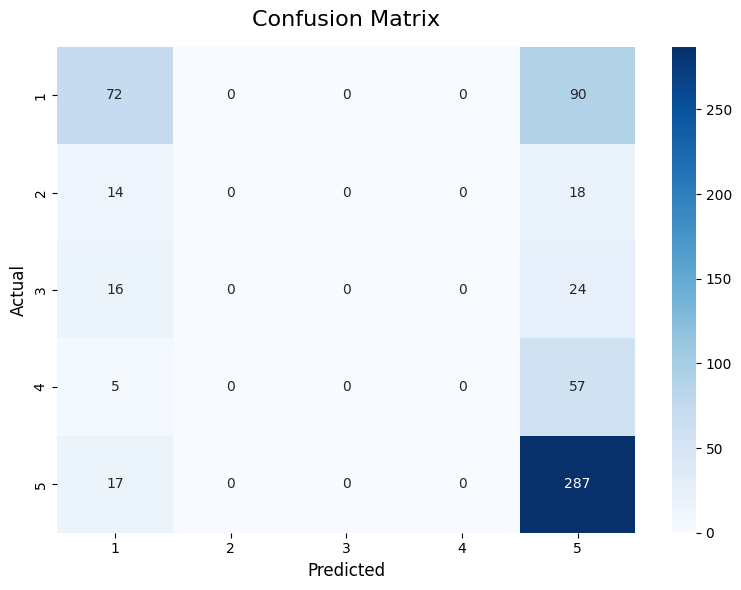

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Train Model
svm_model = LinearSVC(C=1.0, random_state=42, dual=True)
svm_model.fit(X_train_final, y_train)

# Test Model
y_pred = svm_model.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('svm', LinearSVC(random_state=42, dual=True))
])

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100],
    'svm__loss': ['hinge', 'squared_hinge'],

    'svm__intercept_scaling': [1, 2]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_final, y_train)
for param_name in sorted(param_grid.keys()):
    print(f"{param_name}: {grid_search.best_params_[param_name]}")

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

best_svm = grid_search.best_estimator_
final_accuracy = best_svm.score(X_temp_final, y_temp)
print(f"Final Test Accuracy with Best Model: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
svm__C: 100
svm__intercept_scaling: 1
svm__loss: squared_hinge

Best Cross-Validation Accuracy: 66.43%
Final Test Accuracy with Best Model: 67.00%


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           1       0.58      0.44      0.50       162
           2       0.00      0.00      0.00        32
           3       0.00      0.00      0.00        40
           4       0.00      0.00      0.00        62
           5       0.60      0.94      0.74       304

    accuracy                           0.60       600
   macro avg       0.24      0.28      0.25       600
weighted avg       0.46      0.60      0.51       600



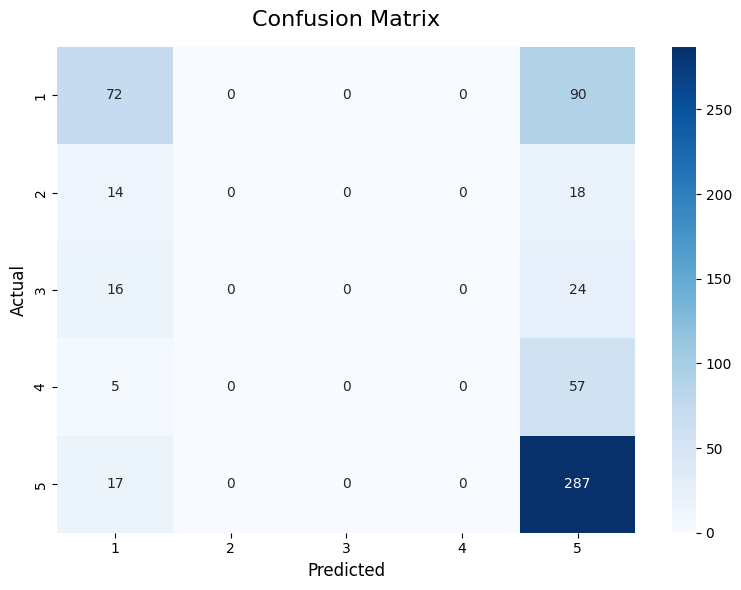

In [ ]:
# Train Model
svm_model_2 = LinearSVC(C=1.0, random_state=42, dual=True)
svm_model_2.fit(X_train_final, y_train)

# Test Model
y_pred = svm_model_2.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

# 5B. Random Forest Classifier

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           1       0.57      0.69      0.62       162
           2       0.00      0.00      0.00        32
           3       0.50      0.03      0.05        40
           4       0.14      0.02      0.03        62
           5       0.70      0.91      0.79       304

    accuracy                           0.65       600
   macro avg       0.38      0.33      0.30       600
weighted avg       0.56      0.65      0.58       600



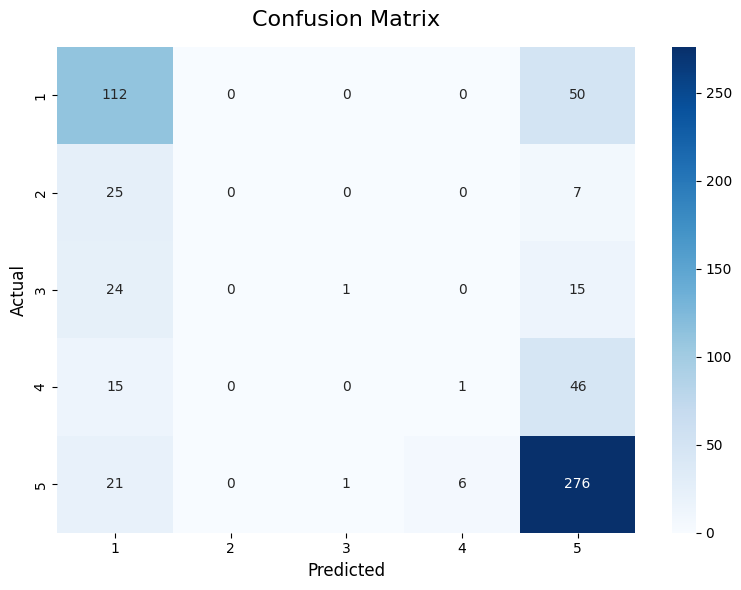

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_final, y_train)

# Test Model
y_pred = rf_model.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
pipeline = Pipeline([
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid = {
    'rf__n_estimators': [50, 100],
    'rf__max_depth': [None, 50, 100],
    'rf__min_samples_split': [2, 5],
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_final, y_train)
for param_name in sorted(param_grid.keys()):
    print(f"{param_name}: {grid_search.best_params_[param_name]}")

print(f"\nBest Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

best_svm = grid_search.best_estimator_
final_accuracy = best_svm.score(X_temp_final, y_temp)
print(f"Final Test Accuracy with Best Model: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
rf__max_depth: None
rf__min_samples_split: 5
rf__n_estimators: 50

Best Cross-Validation Accuracy: 64.21%
Final Test Accuracy with Best Model: 63.33%


              precision    recall  f1-score   support

           1       0.57      0.69      0.62       162
           2       0.00      0.00      0.00        32
           3       0.50      0.03      0.05        40
           4       0.14      0.02      0.03        62
           5       0.70      0.91      0.79       304

    accuracy                           0.65       600
   macro avg       0.38      0.33      0.30       600
weighted avg       0.56      0.65      0.58       600



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


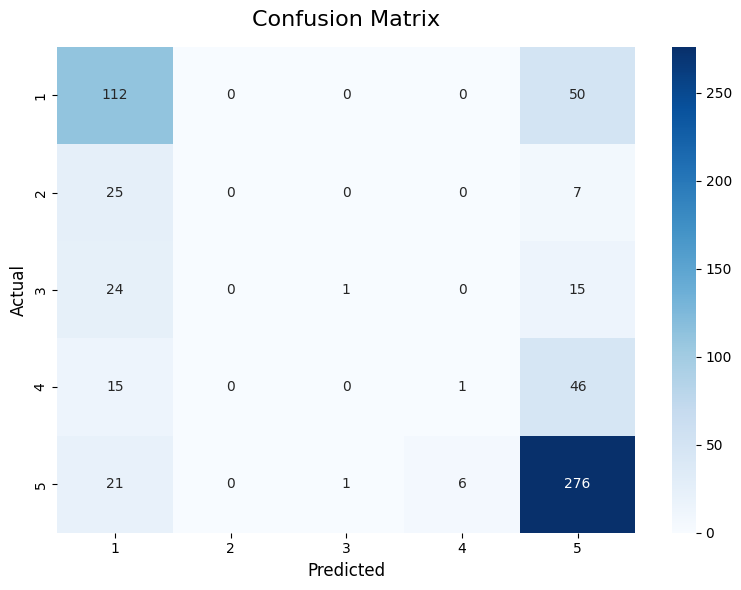

In [ ]:
# Train Model
rf_model_2 = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model_2.fit(X_train_final, y_train)

# Test Model
y_pred = rf_model_2.predict(X_temp_final)
print(classification_report(y_temp, y_pred))

cm = confusion_matrix(y_temp, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])
plt.title('Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.show()

## 5C. LSTM

### a. Building the model

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import classification_report, accuracy_score

embed_dim = 75
max_sen_len = 110

tok = Tokenizer()
tok.fit_on_texts(filtered_tokens_train)

vocab_size = 35000

seq_train = tok.texts_to_sequences(filtered_tokens_train)
seq_val   = tok.texts_to_sequences(filtered_tokens_val)
seq_test  = tok.texts_to_sequences(filtered_tokens_test)

pad_train = pad_sequences(seq_train, maxlen=max_sen_len, padding='post')
pad_val   = pad_sequences(seq_val, maxlen=max_sen_len, padding='post')
pad_test  = pad_sequences(seq_test, maxlen=max_sen_len, padding='post')

In [ ]:
vocabulary_skipgram = model_skipgram.wv.index_to_key
word_vec_dict = {}
for word in vocabulary_skipgram:
    word_vec_dict[word] = model_skipgram.wv.get_vector(word)

embed_matrix = np.zeros(shape=(vocab_size, embed_dim))
for word, i in tok.word_index.items():
    embed_vector = word_vec_dict.get(word)
    if embed_vector is not None:
        embed_matrix[i] = embed_vector

In [ ]:
from tensorflow.keras.optimizers import Adam
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embed_dim,
        weights=[embed_matrix],
        trainable=False,
        mask_zero=True
    ),

    LSTM(64, return_sequences=False),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

In [ ]:
y_train_keras = np.array(y_train) - 1
y_val_keras   = np.array(y_val) - 1
y_test_keras  = np.array(y_test) - 1

history = model.fit(
    pad_train,
    y_train_keras,
    validation_data=(pad_val, y_val_keras),
    epochs=25,
    batch_size=32,
    verbose=1
)


Epoch 1/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.2921 - loss: 1.5811 - val_accuracy: 0.2867 - val_loss: 1.5428
Epoch 2/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.3757 - loss: 1.5052 - val_accuracy: 0.5067 - val_loss: 1.4768
Epoch 3/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.4914 - loss: 1.4520 - val_accuracy: 0.5067 - val_loss: 1.4373
Epoch 4/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5193 - loss: 1.4215 - val_accuracy: 0.5100 - val_loss: 1.4142
Epoch 5/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.5293 - loss: 1.3983 - val_accuracy: 0.5500 - val_loss: 1.3955
Epoch 6/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5271 - loss: 1.3824 - val_accuracy: 0.5467 - val_loss: 1.3789
Epoch 7/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5307 - loss: 1.3605 - val_accuracy: 0.5467 - val_loss: 1.3622
Epoch 8/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5429 - loss: 1.3401 - val_accuracy: 0.5467 - v

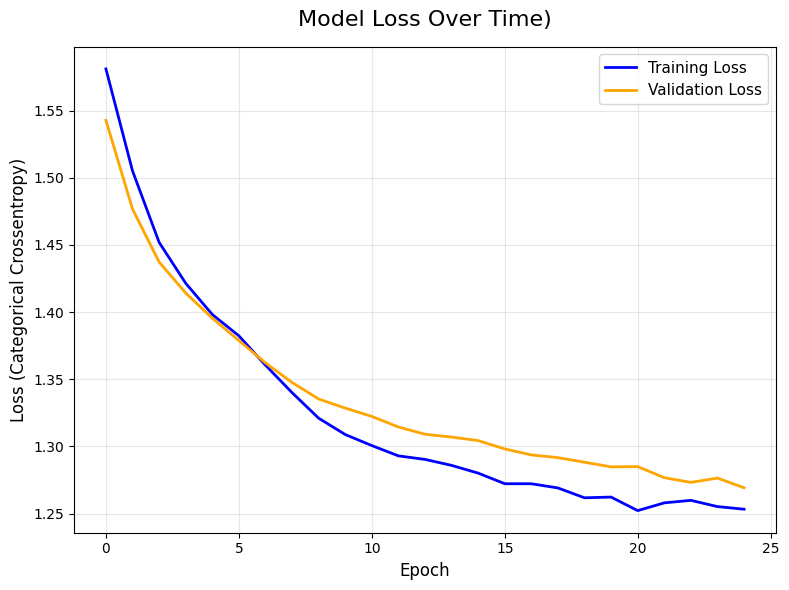

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(history.history['loss'], label='Training Loss', color='blue', linewidth=2)

plt.plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)

plt.title('Model Loss Over Time)', fontsize=16, pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (Categorical Crossentropy)', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
y_pred_probs = model.predict(pad_test)
y_pred_keras = np.argmax(y_pred_probs, axis=1)

y_pred_final = y_pred_keras + 1
y_test_final = y_test_keras + 1


print(f"Overall Accuracy: {accuracy_score(y_test_final, y_pred_final) * 100:.2f}%\n")
print(classification_report(y_test_final, y_pred_final))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Overall Accuracy: 57.00%

              precision    recall  f1-score   support

           1       0.47      0.42      0.44        81
           2       0.00      0.00      0.00        16
           3       0.00      0.00      0.00        20
           4       0.00      0.00      0.00        31
           5       0.60      0.90      0.72       152

    accuracy                           0.57       300
   macro avg       0.21      0.26      0.23       300
weighted avg       0.43      0.57      0.49       300



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


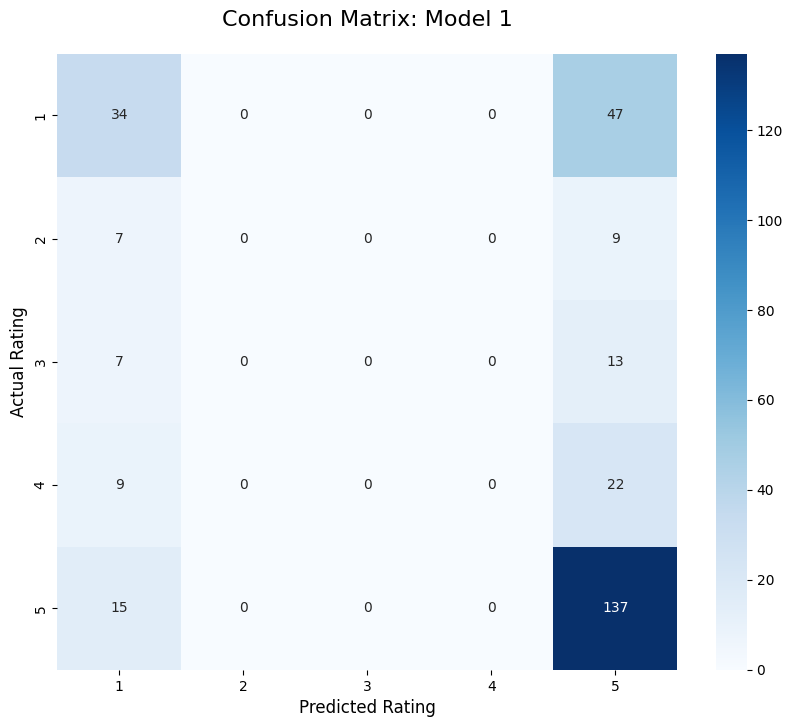

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_final, y_pred_final)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])

plt.title('Confusion Matrix: Model 1', fontsize=16, pad=20)
plt.xlabel('Predicted Rating', fontsize=12)
plt.ylabel('Actual Rating', fontsize=12)
plt.show()

### b. Hyperparameter Tuning

In [ ]:
model2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embed_dim,
        weights=[embed_matrix],
        trainable=False,
        mask_zero=True
    ),

    LSTM(32, return_sequences=False),
    Dense(16, activation='relu'),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

model2.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

In [ ]:
history2 = model2.fit(
    pad_train,
    y_train_keras,
    validation_data=(pad_val, y_val_keras),
    epochs=25,
    batch_size=32,
    verbose=1
)

Epoch 1/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4229 - loss: 1.5814 - val_accuracy: 0.5067 - val_loss: 1.5576
Epoch 2/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.4814 - loss: 1.5381 - val_accuracy: 0.5067 - val_loss: 1.5172
Epoch 3/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4879 - loss: 1.5004 - val_accuracy: 0.5067 - val_loss: 1.4784
Epoch 4/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.4929 - loss: 1.4611 - val_accuracy: 0.5067 - val_loss: 1.4445
Epoch 5/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.4893 - loss: 1.4494 - val_accuracy: 0.5067 - val_loss: 1.4199
Epoch 6/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4907 - loss: 1.4264 - val_accuracy: 0.5067 - val_loss: 1.4005
Epoch 7/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.5043 - loss: 1.4064 - val_accuracy: 0.5067 - val_loss: 1.3842
Epoch 8/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.5093 - loss: 1.3856 - val_accuracy: 0.5067 - v

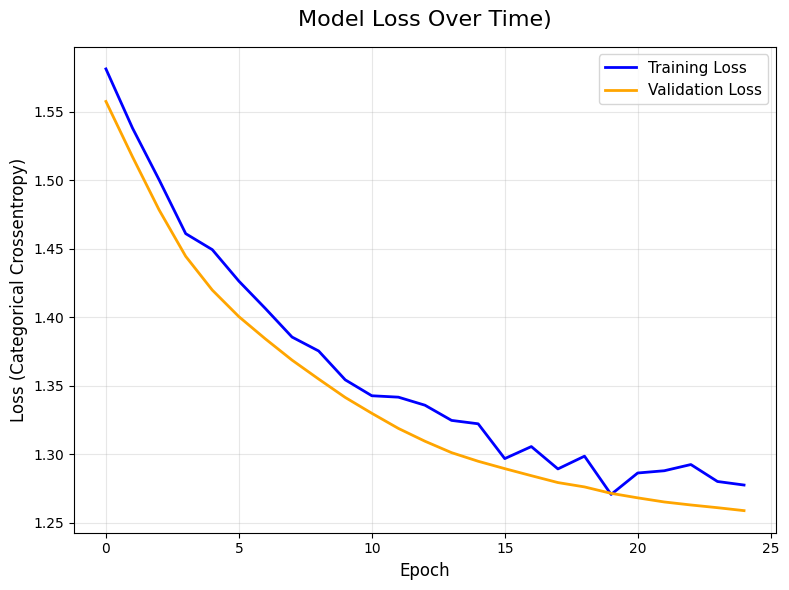

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(history2.history['loss'], label='Training Loss', color='blue', linewidth=2)

plt.plot(history2.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)

plt.title('Model Loss Over Time)', fontsize=16, pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (Categorical Crossentropy)', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
y_pred_probs = model2.predict(pad_test)
y_pred_keras = np.argmax(y_pred_probs, axis=1)

y_pred_final = y_pred_keras + 1
y_test_final = y_test_keras + 1


print(f"Overall Accuracy: {accuracy_score(y_test_final, y_pred_final) * 100:.2f}%\n")
print(classification_report(y_test_final, y_pred_final))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Overall Accuracy: 56.33%

              precision    recall  f1-score   support

           1       0.46      0.40      0.43        81
           2       0.00      0.00      0.00        16
           3       0.00      0.00      0.00        20
           4       0.00      0.00      0.00        31
           5       0.59      0.90      0.72       152

    accuracy                           0.56       300
   macro avg       0.21      0.26      0.23       300
weighted avg       0.43      0.56      0.48       300



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


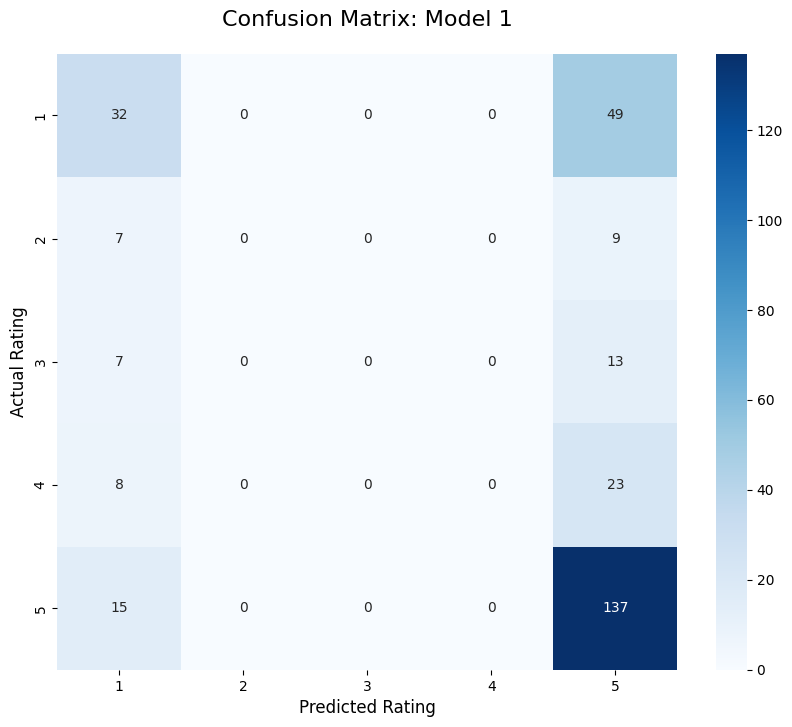

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_final, y_pred_final)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5],
            yticklabels=[1, 2, 3, 4, 5])

plt.title('Confusion Matrix: Model 1', fontsize=16, pad=20)
plt.xlabel('Predicted Rating', fontsize=12)
plt.ylabel('Actual Rating', fontsize=12)
plt.show()